In [8]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [25]:
import re

def classify_decomposition(decomposition: str) -> str:
    """
    Classify a decomposition as 'chain', 'compositional', or 'single-hop'.
    Input is a multiline string with steps (your format).
    """
    steps = [s.strip() for s in decomposition.split("\n") if s.strip()]
    if len(steps) == 1:
        return "single-hop"
    
    # Extract references (#1, #2, …) from each step
    references = [re.findall(r"#\d+", step) for step in steps]
    
    # Check if it's a linear chain
    is_chain = True
    for i in range(1, len(steps)):
        expected = f"#{i}"
        if expected not in steps[i]:
            is_chain = False
            break
    
    # Detect compositional signals
    has_multi_refs = any(len(refs) > 1 for refs in references)
    has_skips = any(
        f"#{i}" in step and f"#{i-1}" not in step
        for i, step in enumerate(steps[1:], start=1)
    )
    
    if is_chain and not has_multi_refs and not has_skips:
        return "chain"
    elif has_multi_refs or has_skips:
        return "compositional"
    else:
        return "chain"  # fallback: shallow chain

In [10]:
musique_dev = load_jsonl("C:/Users/Daniel/Desktop\musique_data_v1.0\data\musique_ans_v1.0_dev.jsonl")

In [19]:
random.sample([sample['question_decomposition'] for sample in musique_dev], 20)

[[{'id': 804367,
   'question': 'Kot Haibat >> country',
   'answer': 'Pakistan',
   'paragraph_support_idx': 7},
  {'id': 160713,
   'question': 'What was the majority religion in the area of British India that become India when #1 was created?',
   'answer': 'Hindu',
   'paragraph_support_idx': 14},
  {'id': 77246,
   'question': 'what is the meaning of #2 in arabic dictionary',
   'answer': 'the country of India',
   'paragraph_support_idx': 10}],
 [{'id': 28841,
   'question': 'Who composed the Concerto in C Major Op 3 6?',
   'answer': 'Antonio Vivaldi',
   'paragraph_support_idx': 1},
  {'id': 547811,
   'question': '#1 >> place of birth',
   'answer': 'Venice',
   'paragraph_support_idx': 11},
  {'id': 41132,
   'question': 'How many times did plague occur in #2 ?',
   'answer': '22',
   'paragraph_support_idx': 15}],
 [{'id': 108336,
   'question': "Which was the creator of Allegory of Isabella d'Este's Coronation?",
   'answer': 'Lorenzo Costa',
   'paragraph_support_idx': 0},

In [42]:
processed_data = []
question_subset = musique_dev #random.sample(musique_dev, 100)
ids = [sample['id'] for sample in question_subset]
questions = [sample['question'] for sample in question_subset]
meta = [sample['question_decomposition'] for sample in question_subset]
summary = []
for ques, deco, idx in zip(questions, meta, ids):
    num_hops = int(idx[0])
    # print(idx[0])
    all_text = ""
    all_text += f"Question: {ques}\n"
    all_text += "Decomposition:\n"
    for step in deco:
        all_text += f"{step['question']} --> {step['answer']}\n"
    answer_class = classify_decomposition(all_text)
    summary.append((answer_class, num_hops))
    processed_data.append({'text': all_text,
                           'type': (answer_class, num_hops)})
    # print(all_text)
    # print(classify_decomposition(all_text))
    # print('-'*100)

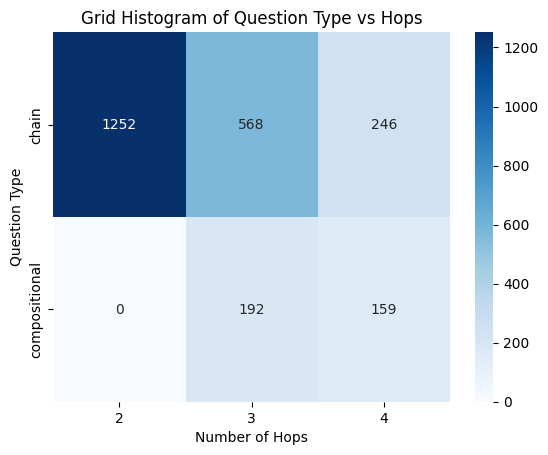

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert to DataFrame
df = pd.DataFrame(summary, columns=['type', 'hops'])

# Create pivot table for grid
grid = df.pivot_table(index='type', columns='hops', aggfunc='size', fill_value=0)

# Plot heatmap
sns.heatmap(grid, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Number of Hops')
plt.ylabel('Question Type')
plt.title('Grid Histogram of Question Type vs Hops')
plt.show()

In [46]:
conditioned_data = [item for item in processed_data if item['type'][0] == 'chain' and item['type'][1] == 4]

In [47]:
len(conditioned_data)

0